In [1]:
from google.colab import files

uploaded = files.upload()  # Select falcon9_launches_labeled.csv when prompted.
csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
if len(csv_names) != 1:
    raise ValueError("Please select exactly one CSV file: falcon9_launches_labeled.csv")
uploaded_csv_name = csv_names[0]
print(f"Selected: {uploaded_csv_name}")

Saving falcon9_launches_labeled.csv to falcon9_launches_labeled.csv
Selected: falcon9_launches_labeled.csv


## 2. Load and check the real data

Google Colab includes the Python data and machine-learning packages used below. This cell checks the library versions, expected columns, target values, and class counts. It does not create example or synthetic observations.

In [2]:
import io
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print(f"Pandas: {pd.__version__} | Scikit-learn: {sklearn.__version__}")
df = pd.read_csv(io.BytesIO(uploaded[uploaded_csv_name]), encoding="utf-8-sig")
required_columns = {
    "Date", "Booster Version", "Launch Site", "Orbit", "Payload Type",
    "Payload Mass (kg)", "Customer Type", "Landing Outcome", "landing_success"
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"This is not the expected labeled project CSV; missing: {sorted(missing_columns)}")
if df.empty:
    raise ValueError("The uploaded CSV has no rows.")

df["landing_success"] = pd.to_numeric(df["landing_success"], errors="raise")
if not df["landing_success"].isin([0, 1]).all():
    raise ValueError("The target must contain only 0 (unsuccessful) and 1 (successful).")
if df["landing_success"].nunique() != 2:
    raise ValueError("Both target classes are needed for a stratified comparison.")

print(f"Rows: {len(df)} | Columns: {len(df.columns)}")
print("Target counts (0 = unsuccessful, 1 = successful):")
display(df["landing_success"].value_counts().sort_index().rename_axis("landing_success").to_frame("launches"))
display(df.head())

Pandas: 2.2.3 | Scikit-learn: 1.6.1
Rows: 104 | Columns: 20
Target counts (0 = unsuccessful, 1 = successful):


,launches
landing_success,
0,13
1,91


,Date,Time (UTC),Booster Version,Dragon Version,Launch Site,Mission,Payload Mass (kg),Payload Mass (lb),Payload Type,Payload Manufacturer,Orbit,Customer,Customer Type,Customer Country,Mission Outcome,Landing Outcome,Drone Ship,Drone Ship Type,Notes,landing_success
0,04-06-2010,18:45:00,F9 v1.0 B0003,Dragon Not Used,CCAFS LC-40,No Payload,NaN,NaN,Demonstration,SpaceX,LEO,SpaceX,Testing,United States of America,Success,Failure (parachute),No Ship Used,No Ship Used,First flight of Falcon 9 v1.0. Used a boilerpl...,0
1,08-12-2010,15:43:00,F9 v1.0 B0004,C101,CCAFS LC-40,"Dragon demo flight C1, two CubeSats, barrel o...",NaN,NaN,Demonstration,SpaceX,LEO (ISS),NASA (COTS) NRO,Government,United States of America,Success,Failure (parachute),No Ship Used,No Ship Used,"Maiden flight of SpaceX's Dragon capsule, cons...",0
2,29-09-2013,16:00:00,F9 v1.1 B1003,Dragon Not Used,VAFB SLC-4E,CASSIOPE,500,1103,Communication Satellite,MDA,Polar LEO,CSA,Business,Canada,Success,Uncontrolled (ocean),No Ship Used,No Ship Used,First commercial mission with a private custom...,0
3,21-09-2014,05:52:00,F9 v1.1 B1010,C106.1,CCAFS LC-40,SpaceX CRS-4,"2,216",4886,Space Station Supplies,NASA,LEO (ISS),NASA (CRS),Government,United States of America,Success,Uncontrolled (ocean),No Ship Used,No Ship Used,"Fourth attempt of a soft ocean touchdown, but ...",0
4,10-01-2015,09:47:00,F9 v1.1 B1012,C107,CCAFS LC-40,SpaceX CRS-5,"2,395",5281,Space Station Supplies,NASA,LEO (ISS),NASA (CRS),Government,United States of America,Success,Failure (drone ship),Just Read The Instructions,Marmac 300,"Following second-stage separation, SpaceX atte...",0


## 3. Choose prediction features

The `Landing Outcome` and `Mission Outcome` columns describe events/outcomes, so they are not predictors. We also exclude `Notes`, mission names, and other post-launch or high-cardinality descriptive fields. Using outcome information to predict the outcome would make a model look better than it really is (data leakage).

The booster serial number is grouped into a broad family such as `F9 B5`; the individual booster identity is not used. Payload mass is parsed as a number, commas are removed, and unparseable/empty values become missing. The malformed historical date becomes a missing year and will be imputed using training data only.

In [3]:
target_column = "landing_success"
model_data = pd.DataFrame(index=df.index)

parsed_dates = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="coerce")
model_data["launch_year"] = parsed_dates.dt.year
model_data["booster_family"] = (
    df["Booster Version"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.extract(r"^(F9\s+(?:v\d+(?:\.\d+)?|FT|B\d+))", expand=False)
    .astype(object)
)
mass_text = df["Payload Mass (kg)"].astype("string").str.replace(",", "", regex=False)
model_data["payload_mass_kg"] = pd.to_numeric(mass_text, errors="coerce")

categorical_features = [
    "Launch Site", "booster_family", "Orbit", "Payload Type", "Customer Type"
]
for column in ("Launch Site", "Orbit", "Payload Type", "Customer Type"):
    values = df[column].astype("string").str.strip().replace("", np.nan)
    model_data[column] = values.astype(object).where(values.notna(), np.nan)

feature_columns = ["launch_year", "payload_mass_kg"] + categorical_features
X = model_data[feature_columns].copy()
y = df[target_column].astype(int).copy()

if X["booster_family"].isna().any():
    raise ValueError("Some booster versions could not be grouped; inspect the source data before modeling.")
print("Model features (all chosen before fitting):", feature_columns)
print("Outcome columns and free-text notes are excluded from X.")
print("Feature preview:")
display(X.head())
print("Missing feature values (these are imputed inside each training pipeline):")
display(X.isna().sum().to_frame("missing values"))

Model features (all chosen before fitting): ['launch_year', 'payload_mass_kg', 'Launch Site', 'booster_family', 'Orbit', 'Payload Type', 'Customer Type']
Outcome columns and free-text notes are excluded from X.
Feature preview:


,launch_year,payload_mass_kg,Launch Site,booster_family,Orbit,Payload Type,Customer Type
0,2010.0,<NA>,CCAFS LC-40,F9 v1.0,LEO,Demonstration,Testing
1,2010.0,<NA>,CCAFS LC-40,F9 v1.0,LEO (ISS),Demonstration,Government
2,2013.0,500,VAFB SLC-4E,F9 v1.1,Polar LEO,Communication Satellite,Business
3,2014.0,2216,CCAFS LC-40,F9 v1.1,LEO (ISS),Space Station Supplies,Government
4,2015.0,2395,CCAFS LC-40,F9 v1.1,LEO (ISS),Space Station Supplies,Government


Missing feature values (these are imputed inside each training pipeline):


,missing values
launch_year,1
payload_mass_kg,5
Launch Site,0
booster_family,0
Orbit,1
Payload Type,0
Customer Type,2


## 4. Make a stratified train/test split

The split happens **before** preprocessing or model fitting. Stratification keeps roughly the same success/unsuccessful proportions in both parts. The random seed makes this particular split repeatable. With so few unsuccessful examples, the test set will still have only a handful of them.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print("Training target counts:")
display(y_train.value_counts().sort_index().rename_axis("landing_success").to_frame("launches"))
print("Test target counts:")
display(y_test.value_counts().sort_index().rename_axis("landing_success").to_frame("launches"))

Training rows: 78 | Test rows: 26
Training target counts:


,launches
landing_success,
0,10
1,68


Test target counts:


,launches
landing_success,
0,3
1,23


## 5. Build leakage-safe preprocessing and models

Each model is placed in a Scikit-learn `Pipeline`. The imputer, scaler, and one-hot encoder are **fit only on the training split** when `pipeline.fit()` runs. The test data is transformed using those training-fitted steps, so information from the test set does not leak into training. Class weighting is used to account for the small unsuccessful class; this can trade precision against recall.

In [5]:
numeric_features = ["launch_year", "payload_mass_kg"]
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

model_definitions = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=2, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1
    ),
    "SVM (RBF)": SVC(
        kernel="rbf", class_weight="balanced", random_state=42
    ),
}

pipelines = {
    name: Pipeline(steps=[("preprocess", preprocessor), ("model", estimator)])
    for name, estimator in model_definitions.items()
}
print("Prepared models:", ", ".join(pipelines))
print("No model has been fitted yet; fitting occurs in the next section.")

Prepared models: Logistic Regression, Decision Tree, Random Forest, SVM (RBF)
No model has been fitted yet; fitting occurs in the next section.


## 6. Train and evaluate on the held-out test data

This cell fits each pipeline on training data and then predicts the untouched test rows. It reports accuracy, precision, recall, and F1 for the positive class (`1` = successful landing), plus a confusion matrix with **actual rows** and **predicted columns** ordered as `[0, 1]`. Because the test set is small and imbalanced, inspect the confusion matrices and class counts as well as accuracy.

In [6]:
results = []
confusion_matrices = {}
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision_success": precision_score(y_test, predictions, pos_label=1, zero_division=0),
        "recall_success": recall_score(y_test, predictions, pos_label=1, zero_division=0),
        "f1_success": f1_score(y_test, predictions, pos_label=1, zero_division=0),
    })
    confusion_matrices[name] = confusion_matrix(y_test, predictions, labels=[0, 1])

results_df = pd.DataFrame(results).set_index("model")
display(results_df.style.format("{:.3f}"))
print("Confusion matrix convention: rows = actual [0, 1], columns = predicted [0, 1].")

,accuracy,precision_success,recall_success,f1_success
model,,,,
Logistic Regression,0.846,0.952,0.870,0.909
Decision Tree,0.885,0.955,0.913,0.933
Random Forest,0.885,0.955,0.913,0.933
SVM (RBF),0.846,0.913,0.913,0.913


Confusion matrix convention: rows = actual [0, 1], columns = predicted [0, 1].


## 7. Compare confusion matrices

For each matrix, the top-left cell is correctly predicted unsuccessful landings, the bottom-right is correctly predicted successful landings, and the off-diagonal cells are errors. These counts come from the held-out records only.

/tmp/ipykernel_800/4116848922.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


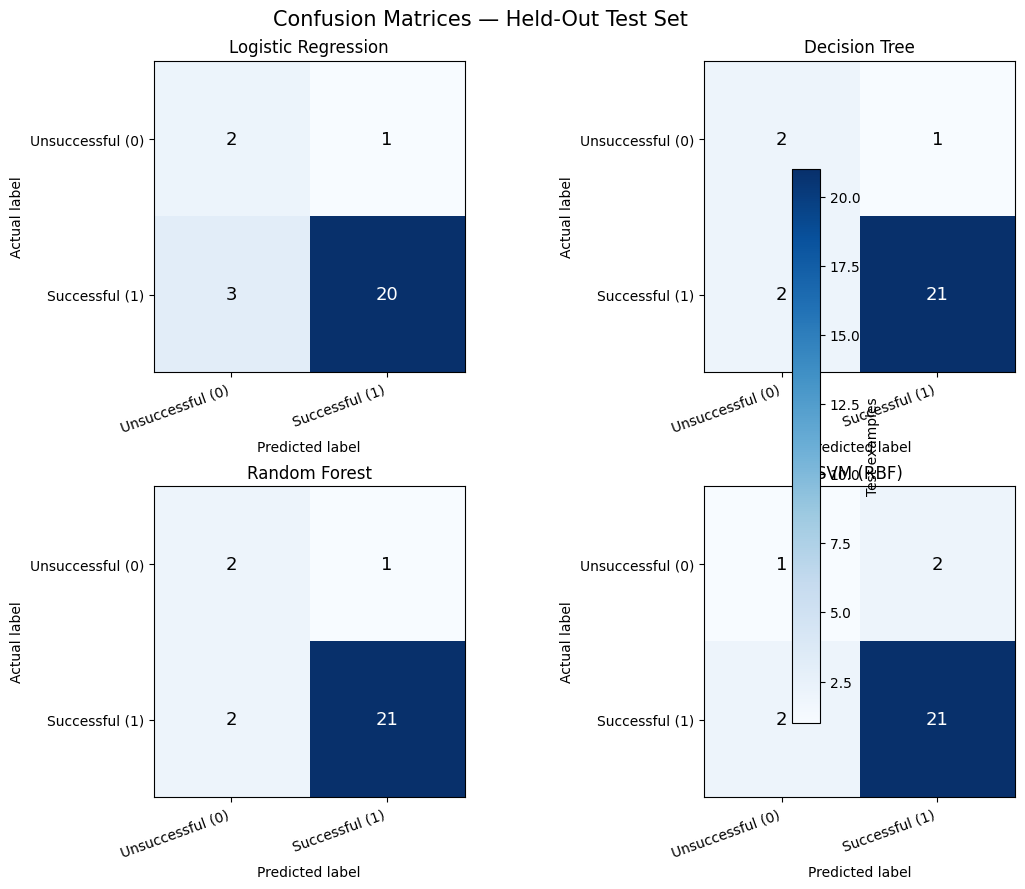

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for axis, (name, matrix) in zip(axes.flat, confusion_matrices.items()):
    image = axis.imshow(matrix, cmap="Blues")
    axis.set_title(name)
    axis.set_xlabel("Predicted label")
    axis.set_ylabel("Actual label")
    axis.set_xticks([0, 1], labels=["Unsuccessful (0)", "Successful (1)"], rotation=20, ha="right")
    axis.set_yticks([0, 1], labels=["Unsuccessful (0)", "Successful (1)"])
    threshold = matrix.max() / 2 if matrix.size else 0
    for row in range(2):
        for column in range(2):
            axis.text(
                column, row, str(matrix[row, column]),
                ha="center", va="center",
                color="white" if matrix[row, column] > threshold else "black",
                fontsize=13,
            )
fig.colorbar(image, ax=axes, shrink=0.8, label="Test examples")
fig.suptitle("Confusion Matrices — Held-Out Test Set", fontsize=15)
fig.tight_layout()
plt.show()

## 8. Interpret carefully

Use the metric table and confusion matrices produced above to compare models; do not select a model from accuracy alone. Precision answers “of predicted successful landings, how many were successful?” Recall answers “of actual successful landings, how many were found?” F1 balances precision and recall. If the project goal changes to detecting unsuccessful landings, calculate those metrics with class 0 as the positive class too.

This is a single train/test split of a small historical dataset—not a robust estimate of performance on future launches. Do not claim that a high score proves reliable real-world prediction. A later evaluation stage can consider repeated stratified cross-validation, uncertainty, feature availability, and the dataset's source limitations. The notebook intentionally does not save model results or a trained model file.